In [1]:
import strahler
import os
os.environ["STRAHLER_PM_BACKEND"] = "simd"
import bz2
from importlib.metadata import version as package_version
if package_version("strahler") != strahler.version():
    raise RuntimeError("Package/library version mismatch. Reinstall strahler and restart the kernel.")
print("strahler package and library versions match")

from IPython.display import HTML, Markdown, display
from strahler.widgets import TreeView
from notebook_support import HERE, table, decomposition_views
from lexicographic_nester import BACKENDS, host_svg
from family_benchmarks import recorded, result_text, fixed_maps


strahler package and library versions match


# Recursive ladders: grow the graph and its height

Recursive ladders add priorities as well as vertices. We follow notebook 08:
look at the hosts and a small answer, compare adaptive search orders, then
check fixed pairs.

The parameter runs through **2, 4, 8, 16, 32, 64, 100, 200 and 300**.
The n=100 and n=200 games come from Keiren's archive; the others use the
same PGSolver construction. Each has **5n vertices**. Unlike the ordinary
ladders in notebook 10, these games need taller hosts as n grows.

We compare AD, symmetric AD and Strahler PM, with and without iterative
shaving. Preprocessing and same-parity priority compression are off; PM
requests the full SIMD kernel.


In [2]:
info, recording = recorded("recursiveladder")
games = info["games"]
by_case = {(r["game"], r["backend"], r["order"]): r for r in recording["rows"]}
table(["n", "vertices", "edges", "priorities", "AD h E/O", "PM h E/O", "t cap"],
      [[g["parameter"], g["vertices"], g["edges"], len(g["raw_priorities"]),
        g["AD_height"], [d + 1 for d in g["PM_depth"]], g["t_max"]] for g in games])


n,vertices,edges,priorities,AD h E/O,PM h E/O,t cap
2,10,19,8,"[5, 5]","[5, 6]",3
4,20,41,14,"[8, 8]","[8, 9]",4
8,40,85,26,"[14, 14]","[14, 15]",5
16,80,173,50,"[26, 26]","[26, 27]",6
32,160,349,98,"[50, 50]","[50, 51]",7
64,320,701,194,"[98, 98]","[98, 99]",8
100,500,1097,302,"[152, 152]","[152, 153]",8
200,1000,2197,602,"[302, 302]","[302, 303]",9
300,1500,3297,902,"[452, 452]","[452, 453]",10


## Host trees

A host $U^k_{t,h}$ supplies the solver's available positions: k bounds the
Strahler number, t sets the leaf allowance, and h counts levels including
the root. PM reads the h−1 edges of a leaf path as measure components.

Here are the n=2 hosts at **(k,t)=(2,1)**. AD has height 5 for both players;
PM has heights 5 and 6. The drawings show the complete hosts.


In [3]:
display(HTML('<div style="display:flex;flex-wrap:wrap;gap:16px">' +
             host_svg(2, 1, 5, "AD E/O and PM Even: h=5") +
             host_svg(2, 1, 6, "PM Odd: h=6") + '</div>'))


## The smallest game's answer

Odd wins all ten vertices. The linked AD views show its decomposition and
the H/T/S blocks. The PM drawings show the occupied measure trees at each
method's first successful lexicographic pair.


Static widget snapshot; rerun for interactive controls.

PM: Odd's occupied tree at the final pair.

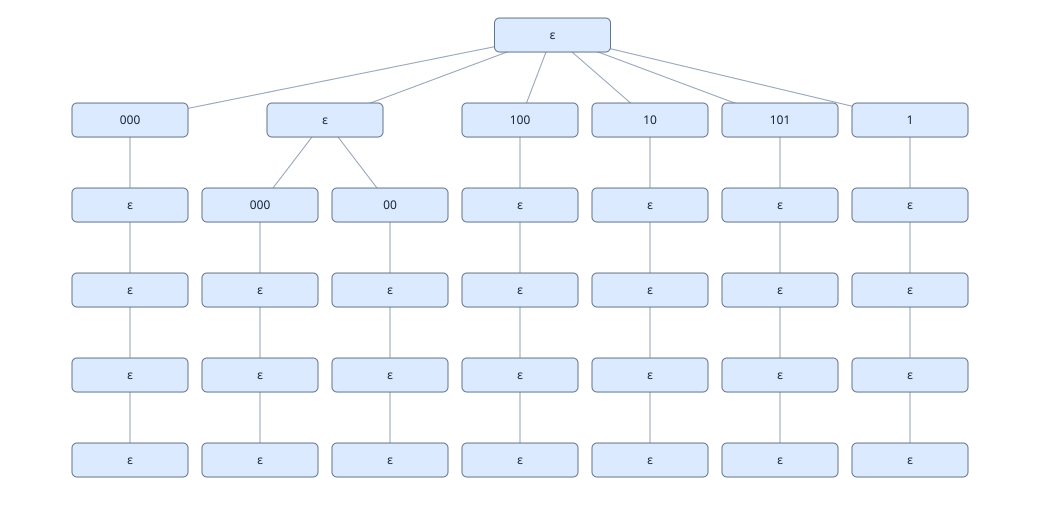

PM+iter: Odd's occupied tree at the final pair.

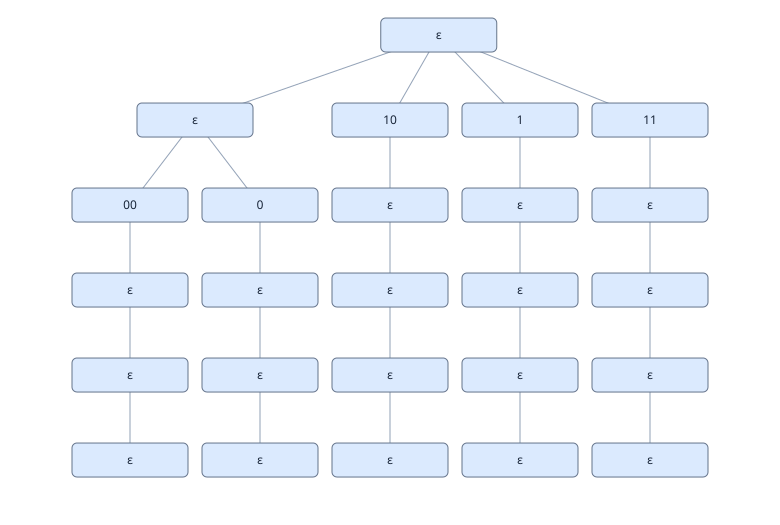

In [4]:
first = games[0]
ladder_game = strahler.Game.from_text(
    bz2.open(HERE / "recursiveladder" / first["file"], "rt").read())
ad_answer = strahler.decompose(ladder_game, "lifting", search="lexicographic")
assert ad_answer.complete
assert strahler.check(ladder_game, ad_answer.trees[1], 1).ok
ordered_ad, blocks_ad = decomposition_views(ad_answer.trees[1], ladder_game)

for backend in ("PM", "PM+iter"):
    answer = strahler.progress_measures(ladder_game, algorithm="strahler",
                                      search="lexicographic", iter_shave=backend.endswith("+iter"))
    assert answer["rounds"][-1]["complete"]
    display(Markdown(f"{backend}: Odd's occupied tree at the final pair."))
    tree = answer["rounds"][-1]["trees"][1]["tree"]
    display(TreeView(tree, mode="tree", edges=False))


## Lexicographic order: one minute per case

We exhaust t before increasing k. The caps are
$t_{max}=\lfloor\log_2 N\rfloor$ and
$k_{max}=\min(h,t_{max}+1)$, including the root.
With +iter, a pair is repeated while shaving removes vertices; the original
caps stay fixed.

Each run has **60 seconds and 2 GiB**, with at most two solvers together.
Times include input, solving, output and verification. Cells give the final
pair and seconds. After a method hits its first limit, larger games are left
beyond its frontier. Notebook execution reads the saved measurements.


In [5]:
def search_table(order):
    table(["n", "vertices", *BACKENDS],
          [[g["parameter"], g["vertices"],
            *[result_text(by_case[g["id"], backend, order]) for backend in BACKENDS]]
           for g in games])

search_table("lexicographic")


n,vertices,AD,AD+iter,AD-sym,AD-sym+iter,PM,PM+iter
2,10,"(1, 0), 0.27 s","(1, 0), 0.27 s","(1, 0), 0.26 s","(1, 0), 0.12 s","(2, 2), 0.13 s","(2, 1), 0.10 s"
4,20,"(2, 1), 0.27 s","(1, 0), 0.18 s","(2, 1), 0.26 s","(1, 0), 0.12 s","(3, 1), 0.16 s","(2, 1), 0.11 s"
8,40,"(2, 1), 0.24 s","(1, 0), 0.27 s","(2, 1), 0.22 s","(1, 0), 0.12 s","(3, 1), 0.12 s","(2, 1), 0.11 s"
16,80,"(2, 1), 0.36 s","(1, 0), 0.22 s","(2, 1), 0.17 s","(1, 0), 0.12 s","(3, 1), 0.15 s","(2, 1), 0.11 s"
32,160,"(2, 1), 0.84 s","(1, 0), 0.22 s","(2, 1), 0.29 s","(1, 0), 0.16 s","(3, 1), 0.38 s","(2, 1), 0.14 s"
64,320,"(2, 1), 8.62 s","(1, 0), 0.65 s","(2, 1), 1.37 s","(1, 0), 0.39 s","(3, 1), 3.55 s","(2, 1), 0.27 s"
100,500,"(2, 1), 41.18 s","(1, 0), 0.97 s","(2, 1), 4.45 s","(1, 0), 1.85 s","(3, 1), 8.01 s","(2, 1), 0.66 s"
200,1000,timeout (60 s cap),"(1, 0), 6.52 s","(2, 1), 33.56 s","(1, 0), 7.37 s",timeout (60 s cap),"(2, 1), 3.96 s"
300,1500,beyond measured frontier,"(1, 0), 22.41 s",timeout (60 s cap),"(1, 0), 23.92 s",beyond measured frontier,"(2, 1), 13.55 s"


All three shaving methods reach n=300. Without shaving, AD and PM reach
n=100, while symmetric AD reaches n=200. The selected k stays small even as
the priority depth grows.


## Ratio and table order

Ratio favours balanced pairs and begins at (1,1). Table order uses the
[precomputed leaf counts](../HOST-ORDER.md) for the larger player height,
then falls back to ratio. Both keep the same limits and shaving rules.


In [6]:
for order in ("ratio", "table"):
    display(Markdown(f"**{order.capitalize()} order**"))
    search_table(order)


**Ratio order**

n,vertices,AD,AD+iter,AD-sym,AD-sym+iter,PM,PM+iter
2,10,"(1, 1), 0.11 s","(1, 1), 0.12 s","(1, 1), 0.11 s","(1, 1), 0.16 s","(2, 2), 0.29 s","(2, 1), 0.20 s"
4,20,"(2, 1), 0.12 s","(1, 1), 0.16 s","(2, 1), 0.13 s","(1, 1), 0.20 s","(3, 2), 0.21 s","(2, 1), 0.15 s"
8,40,"(2, 1), 0.11 s","(1, 1), 0.16 s","(2, 1), 0.18 s","(1, 1), 0.15 s","(3, 2), 0.23 s","(2, 1), 0.17 s"
16,80,"(2, 1), 0.16 s","(1, 1), 0.17 s","(2, 1), 0.21 s","(1, 1), 0.23 s","(3, 2), 0.30 s","(2, 1), 0.17 s"
32,160,"(2, 1), 0.53 s","(1, 1), 0.22 s","(2, 1), 0.25 s","(1, 1), 0.25 s","(3, 2), 0.42 s","(2, 1), 0.21 s"
64,320,"(2, 1), 5.74 s","(1, 1), 0.41 s","(2, 1), 1.04 s","(1, 1), 0.58 s","(3, 2), 1.80 s","(2, 1), 0.39 s"
100,500,"(2, 1), 30.28 s","(1, 1), 1.33 s","(2, 1), 2.91 s","(1, 1), 1.68 s","(3, 2), 6.48 s","(2, 1), 0.71 s"
200,1000,timeout (60 s cap),"(1, 1), 5.12 s","(2, 1), 27.91 s","(1, 1), 6.64 s","(3, 2), 48.56 s","(2, 1), 4.55 s"
300,1500,beyond measured frontier,"(1, 1), 16.01 s",timeout (60 s cap),"(1, 1), 20.78 s",timeout (60 s cap),"(2, 1), 15.47 s"


**Table order**

n,vertices,AD,AD+iter,AD-sym,AD-sym+iter,PM,PM+iter
2,10,"(1, 0), 0.16 s","(1, 0), 0.41 s","(1, 0), 0.12 s","(1, 0), 0.10 s","(2, 2), 0.41 s","(2, 1), 0.16 s"
4,20,"(2, 1), 0.18 s","(1, 0), 0.23 s","(2, 1), 0.15 s","(1, 0), 0.16 s","(3, 1), 0.24 s","(2, 1), 0.14 s"
8,40,"(2, 1), 0.18 s","(1, 0), 0.17 s","(2, 1), 0.19 s","(1, 0), 0.12 s","(3, 1), 0.21 s","(2, 1), 0.27 s"
16,80,"(2, 1), 0.19 s","(1, 0), 0.19 s","(2, 1), 0.21 s","(1, 0), 0.12 s","(3, 1), 0.15 s","(2, 1), 0.14 s"
32,160,"(2, 1), 0.71 s","(1, 0), 0.19 s","(2, 1), 0.42 s","(1, 0), 0.17 s","(3, 1), 0.32 s","(2, 1), 0.21 s"
64,320,"(2, 1), 5.92 s","(1, 0), 0.41 s","(2, 1), 1.18 s","(1, 0), 0.38 s","(3, 1), 1.13 s","(2, 1), 0.33 s"
100,500,"(2, 1), 31.43 s","(1, 0), 0.87 s","(2, 1), 3.53 s","(1, 0), 1.27 s","(3, 1), 3.00 s","(2, 1), 0.72 s"
200,1000,timeout (60 s cap),"(1, 0), 4.76 s","(2, 1), 31.20 s","(1, 0), 7.13 s","(3, 1), 15.71 s","(2, 1), 4.13 s"
300,1500,beyond measured frontier,"(1, 0), 17.38 s",timeout (60 s cap),"(1, 0), 21.18 s","(3, 1), 51.80 s","(2, 1), 14.23 s"


Table order solves n=300 with plain PM in **51.80 s**. Ratio reaches n=200
and lexicographic order n=100. For PM+iter, all three orders solve n=300 in
about **14–15 s**.


## Which fixed pairs solve n=32 and n=100?

We test AD-sym, AD-sym+iter, PM and PM+iter, with 60 seconds and 2 GiB per
pair. All admissible k and t=0…6 enter the scan. With +iter, the fixed pair
is reused while shaving removes vertices.

Green cells solved; red cells finished partial; amber cells hit a limit.
Stars mark confirmed minimal pairs and diamonds mark candidates whose smaller
pairs remain unresolved.

Success is **not monotone in (k,t)**. We cap the scan by skipping larger
pairs after a solve. At fixed height, a solve at (k,t) transfers to (K,T) if
**K=k and T≥t**, or **K>k and T≥t+k−1**. A solved chain (k=1 or t=0)
transfers to every host. See the [embedding proof](../docs/host-monotonicity.md).

Green **⇒** cells follow from this bound and have no measured time. Other green symbols are measured solves. Gray cells remain unknown; amber cells
retain their measured limits.


In [7]:
maps, minima = fixed_maps(info, recording)
display(HTML(maps))
table(["case", "method", "minimal (k,t)", "time/memory limits"],
      [[case, method,
        ", ".join(str(pair) + ("" if pair in confirmed else " ?") for pair in observed) or "none",
        limits or "none"]
       for case, method, confirmed, observed, limits in minima])


case,method,"minimal (k,t)",time/memory limits
recursive ladder n=32,AD-sym,"(2, 1)",none
recursive ladder n=32,AD-sym+iter,"(1, 0)",none
recursive ladder n=32,PM,"(3, 1)",none
recursive ladder n=32,PM+iter,"(2, 1)",none
recursive ladder n=100,AD-sym,"(2, 1)",none
recursive ladder n=100,AD-sym+iter,"(1, 0)",none
recursive ladder n=100,PM,"(3, 1)",none
recursive ladder n=100,PM+iter,"(2, 1)",none


Both mapped sizes have the same confirmed minimal pairs: **(2,1)** for
AD-sym, **(1,0)** for AD-sym+iter, **(3,1)** for PM, and **(2,1)** for
PM+iter. Taller hosts do not force a larger branching bound in these games;
shaving reduces the bound for both algorithms.


## Sources

The archived games are from [Keiren's CC0 dataset](https://doi.org/10.6084/m9.figshare.6004130.v1).
The [PGSolver generator](https://github.com/tcsprojects/pgsolver/blob/d3cd624b61cd66739c45aff9554f6bbdcdd05401/src/lib/generators/recursiveladder.ml)
supplies the smaller and larger parameters; its graph matches both archived
inputs. [The fixture notes](recursiveladder/README.md) give the source details
and commands for repeating the measurements.
